In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
import numpy as np

In [11]:
ROOT = Path().cwd()
DATA_INITIAL = Path("../data_initial").resolve()
DATA = Path("../data").resolve()
FANTOM = DATA / "fantom_cat"
FANTOM_INITIAL = DATA_INITIAL / "fantom_cat"
PREPROCESSING = Path("../preprocessing")

MATRICES = PREPROCESSING / "matrices"
IPS_MATRICES = MATRICES / "ips_matrices"
FIBRO_MATRICES = MATRICES / "fibro_matrices"

INFO = PREPROCESSING / "info"
IPS_INFO = INFO / "ips_info"
FIBRO_INFO = INFO / "fibro_info"

FISHER = PREPROCESSING / "fisher_test"
IPS_FISHER = FISHER / "ips_fisher_exact_test"
FIBRO_FISHER = FISHER / "fibro_fisher_exact_test"

RESULTS = Path("../results")
FISHER_RESULTS = RESULTS / "fisher_test"

JACCARD = PREPROCESSING / "jaccard"
IPS_JACCARD = JACCARD / "ips_jaccard"
FIBRO_JACCARD = JACCARD / "fibro_jaccard"

IMAGES = RESULTS / "images"

In [4]:
def heatmap_pval_blue_red(df, exp):
    from matplotlib.patches import Rectangle

    df["lnc_aso"] = df["lnc"] + "_" + df["aso"]
    cmap = ListedColormap(['blue', 'green', 'black', 'red'])
    bounds = [0, 0.01, 0.05, 0.1, 1]
    norm = BoundaryNorm(bounds, cmap.N)
    
    # Подготовка данных для тепловой карты
    df_for_heatmap = pd.pivot_table(
        data=fisher_results_filt_by_exp[exp][["hm", "lnc_aso", "er", "ea", "wa", "wr"]], 
        index=["lnc_aso"], 
        columns="hm"
    ).sort_index(axis=1, level=1)
    
    # Создание фигуры и осей
    fig, ax = plt.subplots(figsize=(30, 20))
    
    # Добавление прозрачного желтого фона
    ax.add_patch(Rectangle(
        (0, 0),  # Нижний левый угол
        len(df_for_heatmap.columns),  # Ширина (по количеству столбцов)
        len(df_for_heatmap.index),   # Высота (по количеству строк)
        color='yellow',  # Цвет фона
        alpha=0.1,       # Прозрачность фона
        zorder=0         # Слой ниже всех элементов
    ))

    # Построение тепловой карты
    heatmap = sns.heatmap(
        df_for_heatmap, 
        cmap=cmap, 
        norm=norm, 
        annot=False, 
        linewidths=0.5,  # Толщина линий сетки
        linecolor='black',  # Цвет линий сетки
        cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]},
        ax=ax
    )
    
    # Добавление порогового значения на легенду
    colorbar = heatmap.collections[0].colorbar
    colorbar.ax.axhline(0.05, color='yellow', linewidth=2)
    colorbar.ax.text(0.5, 0.05, '0.05', color='yellow', ha='center', va='center', transform=colorbar.ax.transAxes)
    
    # Настройка заголовка и сохранение
    plt.title(f'Heatmap with Custom Threshold Highlighted {exp}', fontsize=25)
    plt.savefig(IMAGES / f"heatmap_pval_blue_red_{exp}.png")
    plt.show()


In [5]:
fisher_results_filt_by_exp = {}
for exp in ["fibro", "ips"]:
    to_file = JACCARD / f"{exp}-fisher-significant.tsv"
    fisher_results_filt = pd.read_csv(to_file, sep="\t")
    if exp == "fibro":
        fisher_results_filt["aso"] = fisher_results_filt["aso"].apply(lambda x: "_".join(x.split("_")[1:]))
    fisher_results_filt["lnc-hm"] = fisher_results_filt["lnc"] + "-" + fisher_results_filt["hm"]
    fisher_results_filt["lnc-aso-hm"] = fisher_results_filt["lnc"] + "-" + fisher_results_filt["aso"] + "-" + fisher_results_filt["hm"]
    fisher_results_filt_by_exp[exp] = fisher_results_filt    

In [6]:
fisher_results_filt_by_exp["fibro"]

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm
0,H3K9me3,ENSG00000163364,G0163364_AD_01,1.000000e+00,1.917683e-03,1.000000,1.000000,AC017048.3,AC017048.3-H3K9me3,AC017048.3-G0163364_AD_01-H3K9me3
1,H3K9me3,ENSG00000214548,G0214548_01,6.904775e-01,6.172479e-04,0.001780,0.696110,MEG3,MEG3-H3K9me3,MEG3-G0214548_01-H3K9me3
2,H3K9me3,ENSG00000214548,G0214548_AD_09,1.000000e+00,1.050761e-07,1.000000,0.000695,MEG3,MEG3-H3K9me3,MEG3-G0214548_AD_09-H3K9me3
3,H3K9me3,ENSG00000223478,G0223478_03,8.484336e-04,9.853195e-01,1.000000,1.000000,RP11-545E17.3,RP11-545E17.3-H3K9me3,RP11-545E17.3-G0223478_03-H3K9me3
4,H3K9me3,ENSG00000225470,G0225470_AD_04,1.000000e+00,1.000000e+00,0.002088,1.000000,JPX,JPX-H3K9me3,JPX-G0225470_AD_04-H3K9me3
...,...,...,...,...,...,...,...,...,...,...
277,H3K4me1,ENSG00000268895,G0268895_01,1.000000e+00,4.303351e-01,0.005312,1.000000,A1BG-AS1,A1BG-AS1-H3K4me1,A1BG-AS1-G0268895_01-H3K4me1
278,H3K4me1,ENSG00000268895,G0268895_03,7.864094e-04,4.142816e-01,0.000205,1.000000,A1BG-AS1,A1BG-AS1-H3K4me1,A1BG-AS1-G0268895_03-H3K4me1
279,H3K4me1,ENSG00000269834,G0269834_02,6.742146e-03,5.148661e-01,0.255875,1.000000,CTD-3018O17.3,CTD-3018O17.3-H3K4me1,CTD-3018O17.3-G0269834_02-H3K4me1
280,H3K4me1,ENSG00000269834,G0269834_AD_02,1.579246e-07,3.774202e-01,0.443793,1.000000,CTD-3018O17.3,CTD-3018O17.3-H3K4me1,CTD-3018O17.3-G0269834_AD_02-H3K4me1


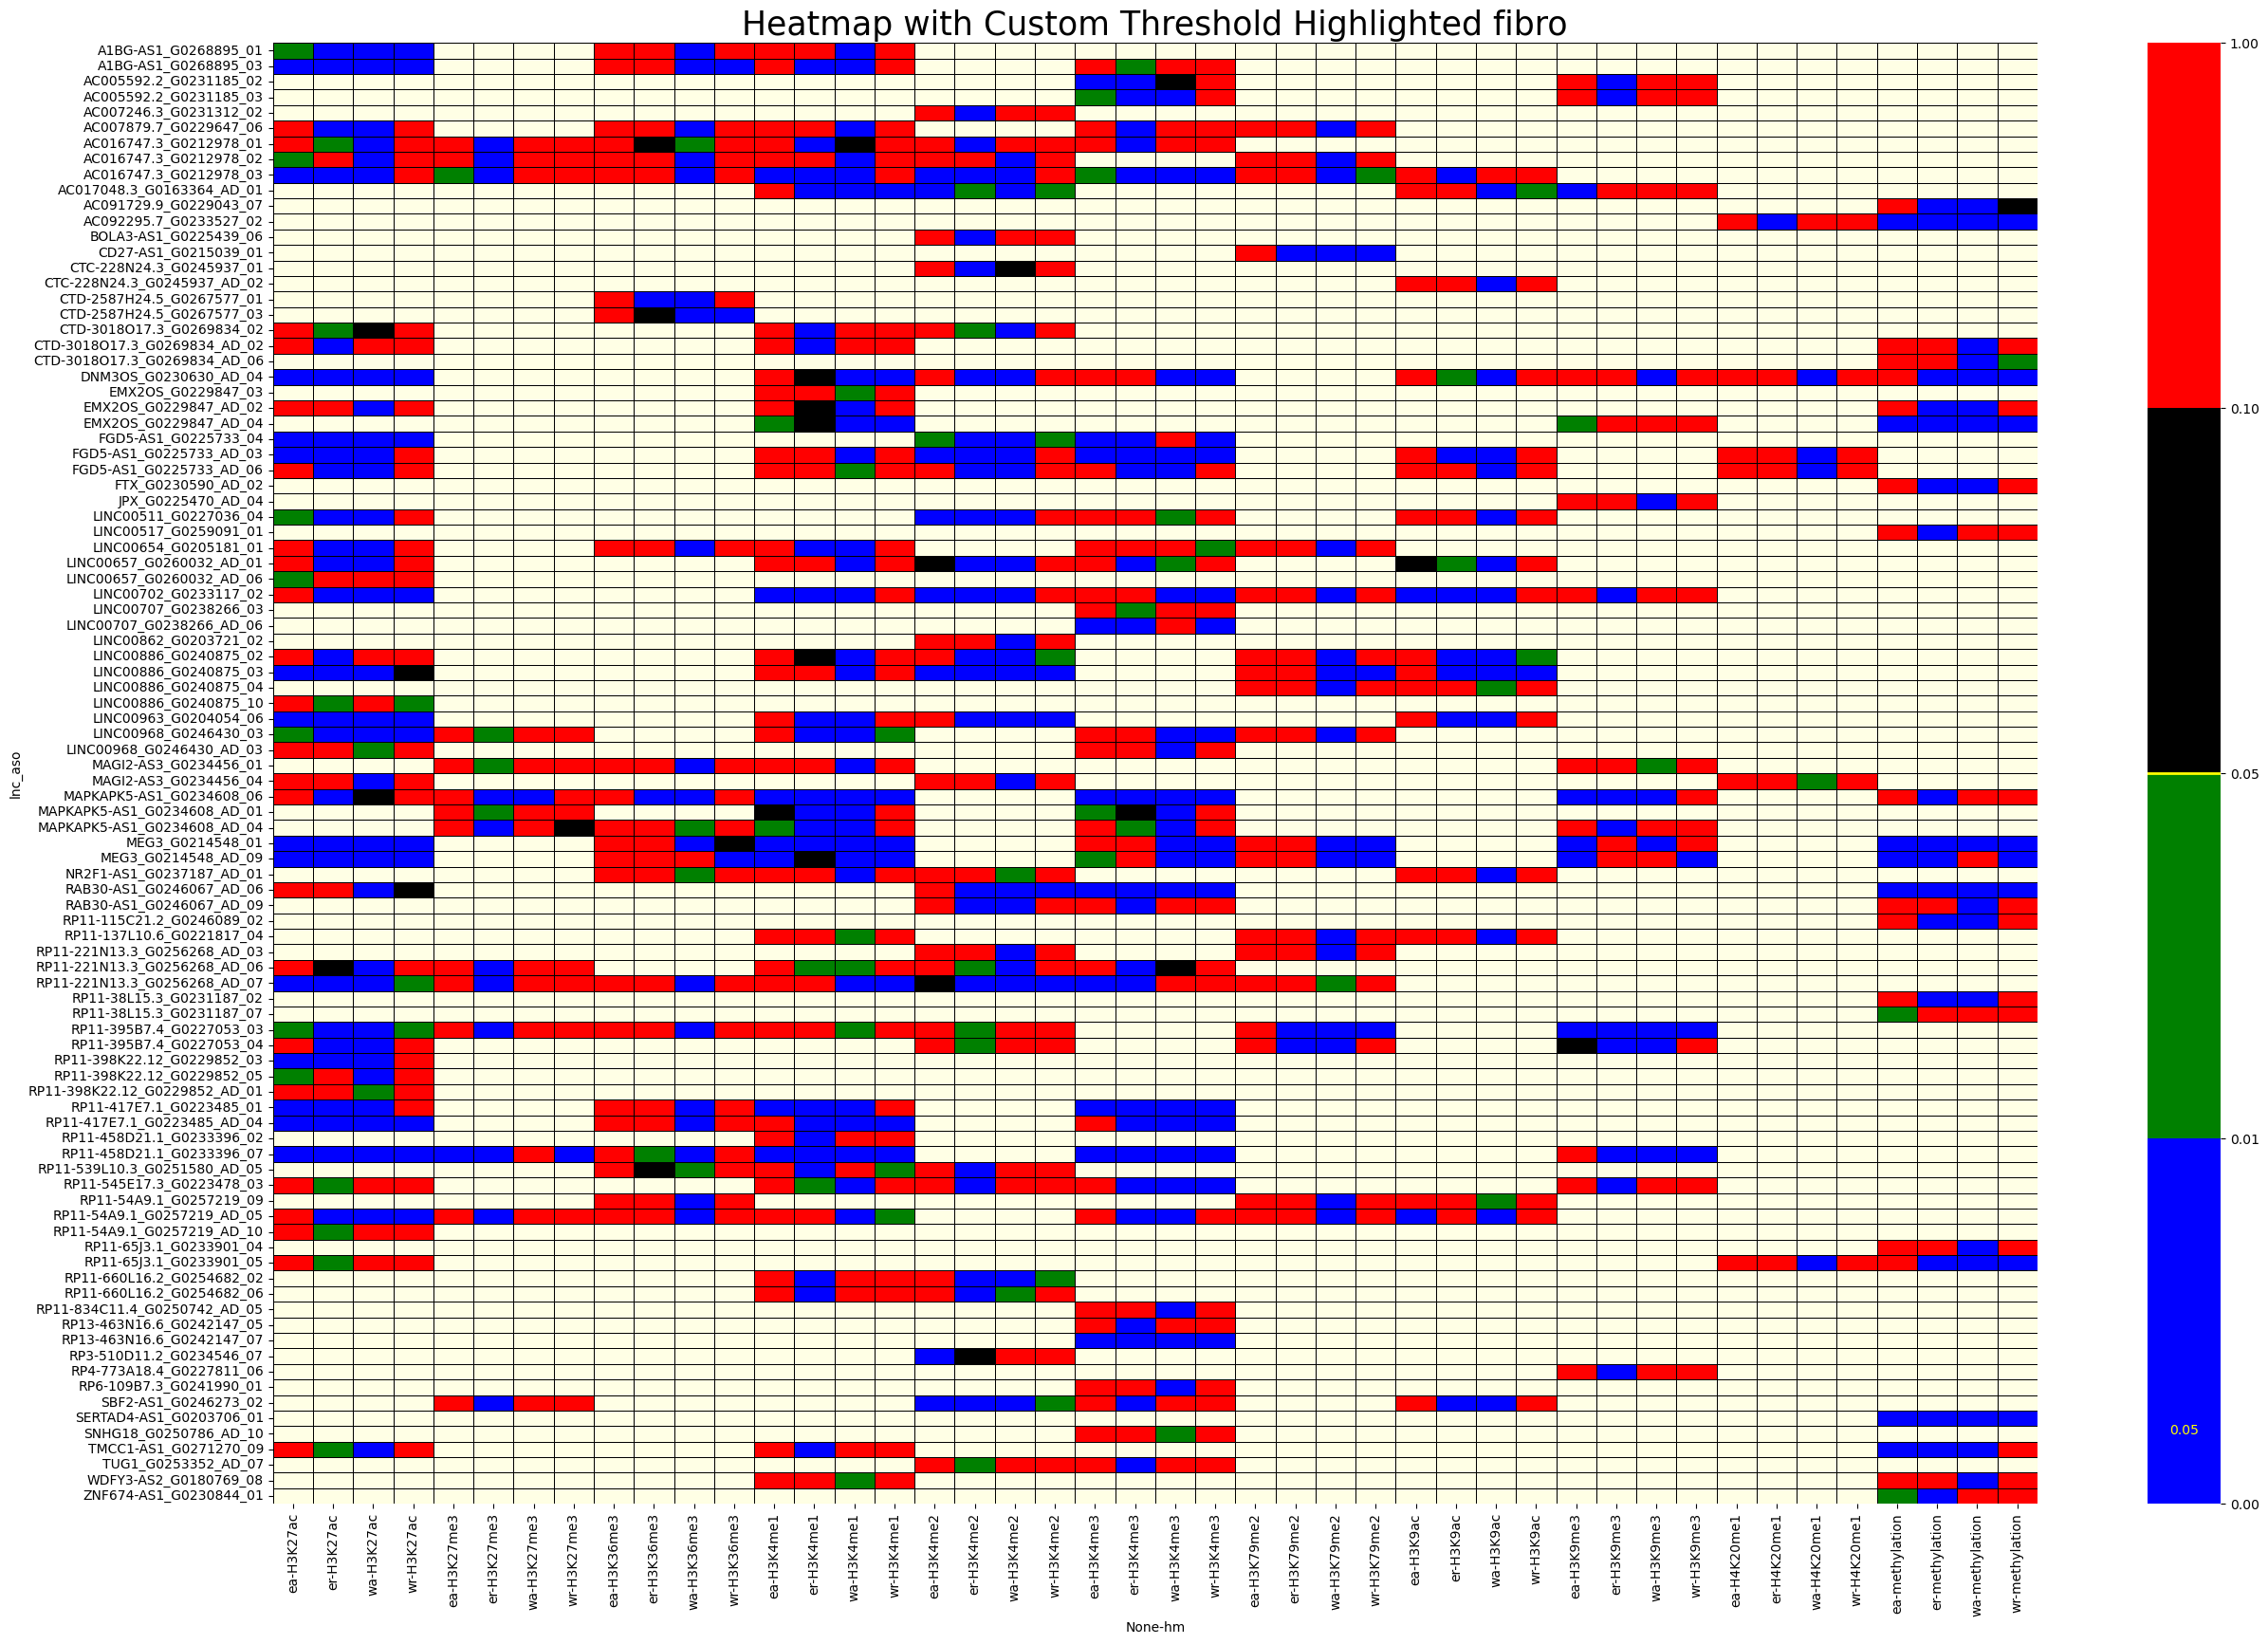

In [7]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"], exp="fibro")

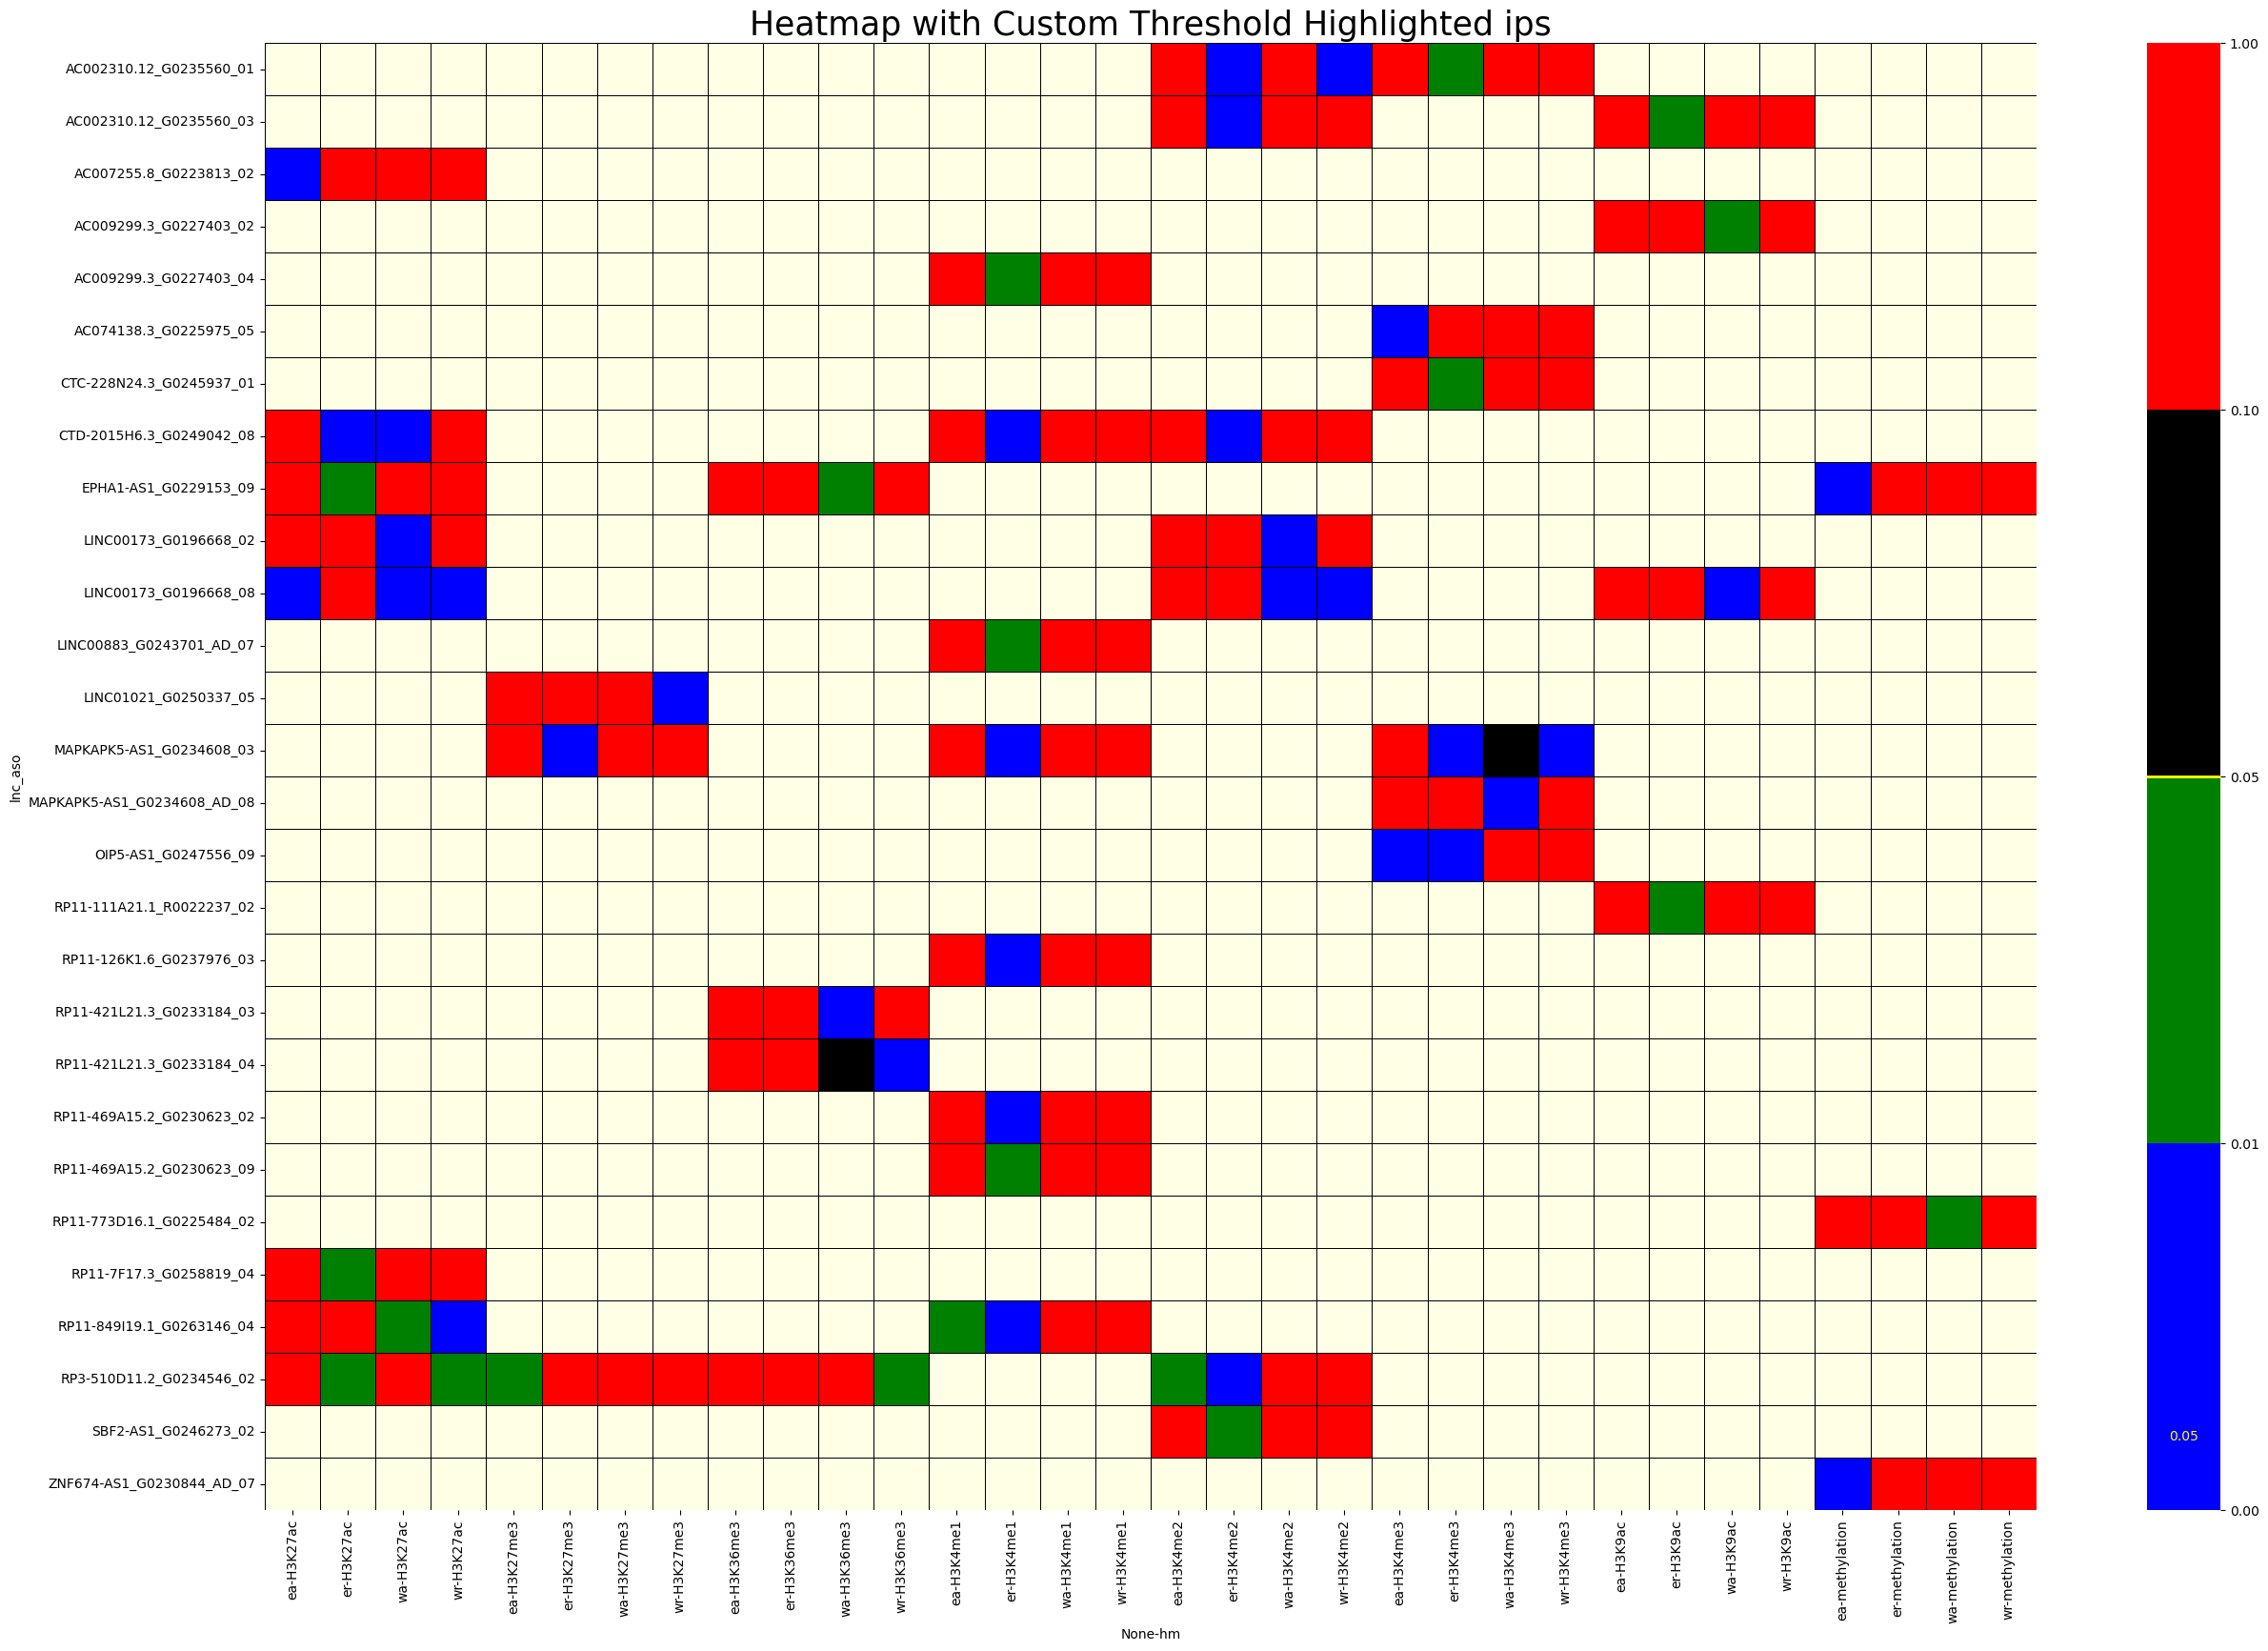

In [6]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["ips"], exp="ips")

## Сравнение результатов между тканями

In [119]:
set(fisher_results_filt_by_exp["ips"]["lnc-aso-hm"]) & set(fisher_results_filt_by_exp["fibro"]["lnc-aso-hm"])

{'SBF2-AS1-G0246273_02-H3K4me2'}

In [120]:
shared_pairs = set(fisher_results_filt_by_exp["ips"]["lnc-hm"]) & set(fisher_results_filt_by_exp["fibro"]["lnc-hm"])
shared_pairs

{'MAPKAPK5-AS1-H3K27me3',
 'MAPKAPK5-AS1-H3K4me1',
 'MAPKAPK5-AS1-H3K4me3',
 'RP3-510D11.2-H3K4me2',
 'SBF2-AS1-H3K4me2',
 'ZNF674-AS1-methylation'}

In [121]:
mask = fisher_results_filt_by_exp["ips"]["lnc-hm"].isin(shared_pairs)
ips_shared_pairs = fisher_results_filt_by_exp["ips"][mask].sort_values(by="lnc-hm")
ips_shared_pairs

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm
9,H3K27me3,ENSG00000234608,G0234608_03,0.001592,1.000000,1.000000e+00,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_03-H3K27me3
32,H3K4me1,ENSG00000234608,G0234608_03,0.000361,1.000000,1.000000e+00,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_03-H3K4me1
38,H3K4me3,ENSG00000234608,G0234608_03,0.002337,1.000000,5.185953e-02,1.621916e-12,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_03-H3K4me3
39,H3K4me3,ENSG00000234608,G0234608_AD_08,1.000000,1.000000,1.061650e-08,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_08-H3K4me3
20,H3K4me2,ENSG00000234546,G0234546_02,0.005422,0.039069,1.000000e+00,1.049887e-01,RP3-510D11.2,RP3-510D11.2-H3K4me2,RP3-510D11.2-G0234546_02-H3K4me2
23,H3K4me2,ENSG00000246273,G0246273_02,0.015662,0.719485,2.334334e-01,1.000000e+00,SBF2-AS1,SBF2-AS1-H3K4me2,SBF2-AS1-G0246273_02-H3K4me2
13,methylation,ENSG00000230844,G0230844_AD_07,1.000000,0.001116,7.609634e-01,7.717996e-01,ZNF674-AS1,ZNF674-AS1-methylation,ZNF674-AS1-G0230844_AD_07-methylation


In [122]:
mask = fisher_results_filt_by_exp["fibro"]["lnc-hm"].isin(shared_pairs)
fibro_shared_pairs = fisher_results_filt_by_exp["fibro"][mask].sort_values(by="lnc-hm")
fibro_shared_pairs

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm
112,H3K27me3,ENSG00000234608,G0234608_06,1.065815e-67,0.268351,3.911268e-04,0.696211,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_06-H3K27me3
113,H3K27me3,ENSG00000234608,G0234608_AD_01,3.584434e-02,1.000000,1.000000e+00,0.672234,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_AD_01-H3K27me3
114,H3K27me3,ENSG00000234608,G0234608_AD_04,7.061397e-12,1.000000,1.000000e+00,0.053986,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_AD_04-H3K27me3
218,H3K4me1,ENSG00000234608,G0234608_06,4.147803e-163,0.000313,6.585890e-10,0.007997,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_06-H3K4me1
219,H3K4me1,ENSG00000234608,G0234608_AD_01,2.702283e-08,0.068848,1.215452e-04,0.554661,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_AD_01-H3K4me1
220,H3K4me1,ENSG00000234608,G0234608_AD_04,9.020846e-03,0.020533,1.569999e-14,0.338966,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_AD_04-H3K4me1
172,H3K4me3,ENSG00000234608,G0234608_06,1.228645e-82,0.000011,2.492339e-34,0.000260,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_06-H3K4me3
173,H3K4me3,ENSG00000234608,G0234608_AD_01,8.913402e-02,0.019394,1.821406e-08,0.307508,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_01-H3K4me3
174,H3K4me3,ENSG00000234608,G0234608_AD_04,2.198126e-02,0.110536,1.198424e-21,1.000000,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_04-H3K4me3
137,H3K4me2,ENSG00000234546,G0234546_07,8.453428e-02,0.000799,1.000000e+00,1.000000,RP3-510D11.2,RP3-510D11.2-H3K4me2,RP3-510D11.2-G0234546_07-H3K4me2


<Axes: ylabel='lnc-aso-hm'>

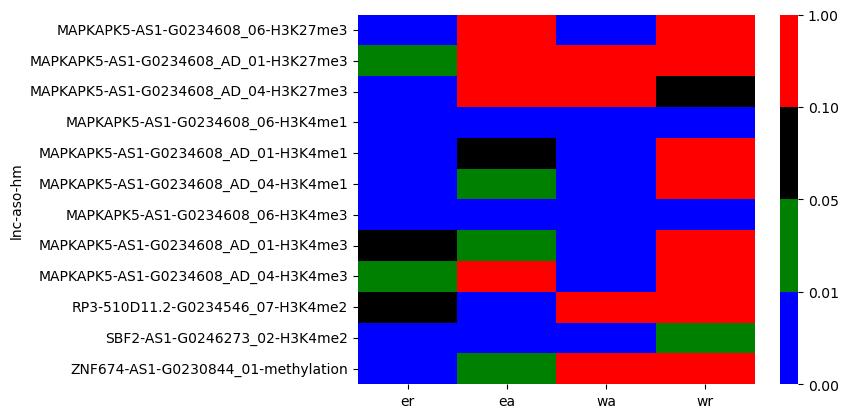

In [124]:
cmap = ListedColormap(['blue', 'green', 'black', 'red'])
bounds = [0, 0.01, 0.05, 0.1, 1]
norm = BoundaryNorm(bounds, cmap.N)
sns.heatmap(fibro_shared_pairs[["lnc-aso-hm", "er", "ea", "wa", "wr"]].set_index("lnc-aso-hm"), cmap=cmap, cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]}, norm=norm)

<Axes: ylabel='lnc-aso-hm'>

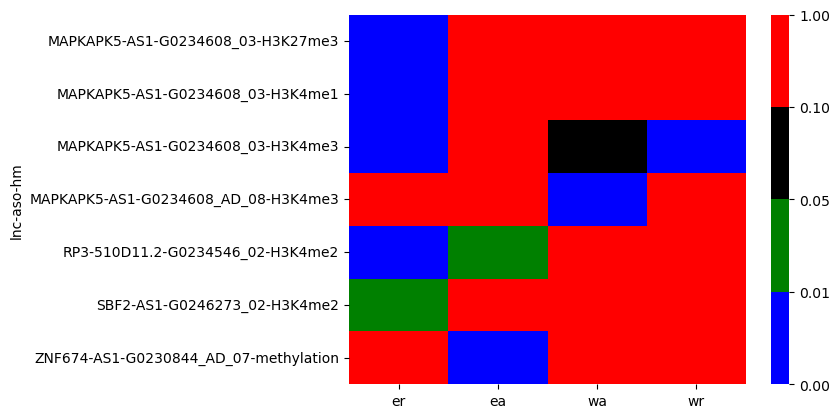

In [125]:
sns.heatmap(ips_shared_pairs[["lnc-aso-hm", "er", "ea", "wa", "wr"]].set_index("lnc-aso-hm"), cmap=cmap, cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]}, norm=norm)

In [ ]:
CTD